# Hotel Booking — Cancellation Data Analysis

**Portfolio focus:** SQL, Python/pandas, data exploration, cancellation patterns, business insights and a statistical comparison.  
**Data source:** [TidyTuesday hotels.csv](https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv).  
**Scope:** Descriptive and diagnostic analysis only; predictive modeling is saved in a separate notebook for later review.

The Python and SQL code below is the author's original code, kept unchanged. Headings and explanations were organized for readability.

## 01. Dataset Overview

Load the dataset and inspect its structure before aggregating any results.


In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"

hotel_df = pd.read_csv(url)

hotel_df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Dataset shape, fields, and types


In [2]:
hotel_df.shape

(119390, 32)

In [3]:
hotel_df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [4]:
hotel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### Initial category checks


In [5]:
hotel_df["hotel"].unique()

array(['Resort Hotel', 'City Hotel'], dtype=object)

In [6]:
hotel_df["previous_bookings_not_canceled"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 20, 21, 22, 23, 24, 25, 27, 28, 29, 30, 19, 26, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72])

In [7]:
hotel_df["market_segment"].unique()

array(['Direct', 'Corporate', 'Online TA', 'Offline TA/TO',
       'Complementary', 'Groups', 'Undefined', 'Aviation'], dtype=object)

### SQL environment


In [8]:
%pip install -q duckdb

All following SQL analysis uses the **existing original DuckDB SQL** against the `hotel_df` DataFrame. The same data is examined with pandas where it adds a different analytical view.


## 02. Cancellation Overview — Hotel and Market Segment

**Business question:** Which hotel type and sales segment have higher cancellation rates?


### Cancellation rate by hotel


In [9]:
import duckdb

query = """
SELECT
    hotel,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    100.0 * SUM(is_canceled) / COUNT(*) AS cancellation_rate_pct
FROM hotel_df
GROUP BY hotel
ORDER BY cancellation_rate_pct DESC;
"""

result = duckdb.sql(query).df()

display(result)

,hotel,total_bookings,canceled_bookings,cancellation_rate_pct
0,City Hotel,79330,33102.0,41.726963
1,Resort Hotel,40060,11122.0,27.763355


> **Original finding:** City Hotels have a cancellation rate of 41.73%, compared with 27.76% for Resort Hotels. This suggests that City Hotels may require greater attention to cancellation management.


### Distribution of bookings between hotel types


In [10]:
query = """

SELECT
    hotel,
    COUNT(*) AS total_bookings,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS hotel_pct
FROM hotel_df
GROUP BY hotel;
"""

result = duckdb.sql(query).df()
display(result)


,hotel,total_bookings,hotel_pct
0,Resort Hotel,40060,33.55
1,City Hotel,79330,66.45


### Cancellation rate by market segment


In [11]:
query = """

SELECT market_segment,
      COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    100.0 * SUM(is_canceled) / COUNT(*) AS cancellation_rate_pct
FROM hotel_df
GROUP BY market_segment
ORDER BY cancellation_rate_pct DESC;
"""

result = duckdb.sql(query).df()

display(result)

,market_segment,total_bookings,canceled_bookings,cancellation_rate_pct
0,Undefined,2,2.0,100.000000
1,Groups,19811,12097.0,61.062036
2,Online TA,56477,20739.0,36.721143
3,Offline TA/TO,24219,8311.0,34.316033
4,Aviation,237,52.0,21.940928
5,Corporate,5295,992.0,18.734655
6,Direct,12606,1934.0,15.341901
7,Complementary,743,97.0,13.055182


**Interpretation:** Compare **canceled booking counts** with **cancellation rate**. A large segment can contribute more cancellations even with a lower rate.


## 03. Lead Time vs Cancellation

**Business question:** Are reservations made further ahead more likely to be canceled?


Lead time is the number of days between booking and scheduled arrival.


### Mean and median lead time by outcome


In [12]:
query = """
SELECT
    is_canceled,
    ROUND(AVG(lead_time), 2) AS avg_lead_time,
    ROUND(MEDIAN(lead_time), 2) AS median_lead_time
FROM hotel_df
GROUP BY is_canceled
"""

result = duckdb.sql(query).df()
display(result)

,is_canceled,avg_lead_time,median_lead_time
0,1,144.85,113.0
1,0,79.98,45.0


> **Original finding:** Canceled bookings have a significantly longer average lead time (144.85 days) compared with non-canceled bookings (79.98 days). This suggests that bookings made further in advance may be associated with a higher risk of cancellation.


### Cancellation by lead-time group


In [13]:
import pandas as pd
import duckdb

query = """
WITH lead_groups AS (
    SELECT
        is_canceled,
        CASE
            WHEN lead_time <= 30 THEN '0-30 days'
            WHEN lead_time <= 90 THEN '31-90 days'
            ELSE '91+ days'
        END AS lead_time_group
    FROM hotel_df
)

SELECT
    lead_time_group,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(
        100.0 * SUM(is_canceled) / COUNT(*),
        2
    ) AS cancellation_rate_pct
FROM lead_groups
GROUP BY lead_time_group
ORDER BY
    CASE lead_time_group
        WHEN '0-30 days' THEN 1
        WHEN '31-90 days' THEN 2
        WHEN '91+ days' THEN 3
    END
"""

result = duckdb.sql(query).df()

display(result)

,lead_time_group,total_bookings,canceled_bookings,cancellation_rate_pct
0,0-30 days,38706,7185.0,18.56
1,31-90 days,29553,11141.0,37.70
2,91+ days,51131,25898.0,50.65


> **Original finding:** Bookings made more than 90 days in advance have the highest cancellation rate at 50.65%, compared with 18.56% for bookings made within 30 days. This suggests that long lead times may be a useful indicator of cancellation risk and should be investigated further.


### Interaction: lead time × hotel type


In [14]:
query = """
WITH lead_groups AS (
    SELECT
        hotel,
        is_canceled,
        CASE
            WHEN lead_time <= 30 THEN '0-30 days'
            WHEN lead_time <= 90 THEN '31-90 days'
            ELSE '91+ days'
        END AS lead_time_group
    FROM hotel_df
)

SELECT
    hotel,
    lead_time_group,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(
        100.0 * SUM(is_canceled) / COUNT(*),
        2
    ) AS cancellation_rate_pct
FROM lead_groups
GROUP BY hotel, lead_time_group
ORDER BY
    hotel,
    CASE lead_time_group
        WHEN '0-30 days' THEN 1
        WHEN '31-90 days' THEN 2
        WHEN '91+ days' THEN 3
    END
"""

result = duckdb.sql(query).df()

display(result)

,hotel,lead_time_group,total_bookings,canceled_bookings,cancellation_rate_pct
0,City Hotel,0-30 days,23362,5199.0,22.25
1,City Hotel,31-90 days,20797,8300.0,39.91
2,City Hotel,91+ days,35171,19603.0,55.74
3,Resort Hotel,0-30 days,15344,1986.0,12.94
4,Resort Hotel,31-90 days,8756,2841.0,32.45
5,Resort Hotel,91+ days,15960,6295.0,39.44


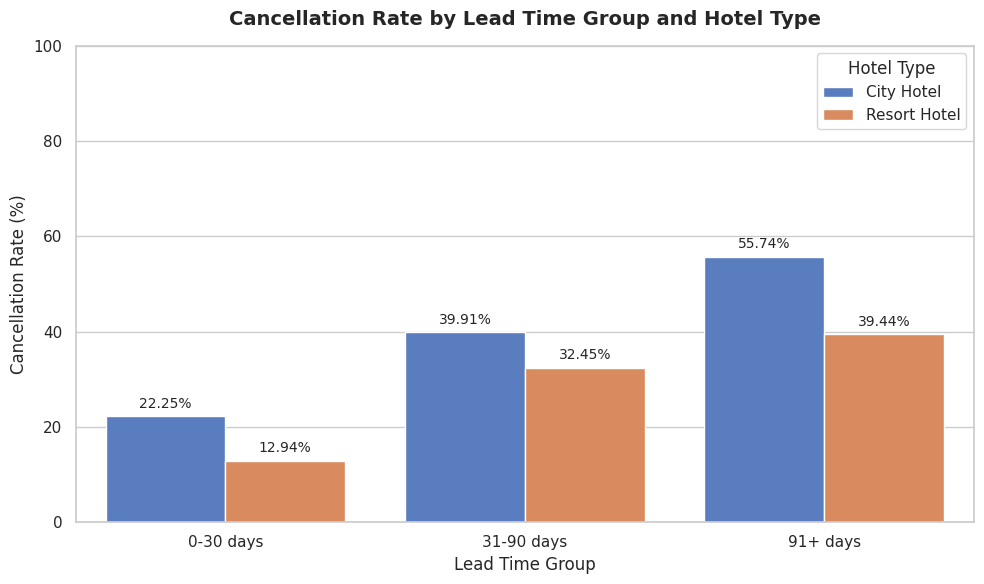

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าสไตล์ของกราฟ
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# สร้าง Grouped Bar Chart เปรียบเทียบสองประเภทโรงแรม
ax = sns.barplot(
    x="lead_time_group",
    y="cancellation_rate_pct",
    hue="hotel",
    data=result,
    palette="muted"
)

# เพิ่มป้ายแสดงตัวเลขบนแท่งกราฟ
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.2f}%',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=10)

# ตั้งชื่อกราฟและแกน
plt.title("Cancellation Rate by Lead Time Group and Hotel Type", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Lead Time Group", fontsize=12)
plt.ylabel("Cancellation Rate (%)", fontsize=12)
plt.ylim(0, 100)
plt.legend(title="Hotel Type")

plt.tight_layout()
plt.show()

## 04. Deposit Type and Cancellation

**Business question:** Does deposit type correlate with cancellations, and do segment or lead-time differences help explain the pattern?


### Deposit type — cancellation rate


In [16]:
query  = """
SELECT deposit_type,
      COUNT(*) AS total_bookings,
      SUM(is_canceled) AS canceled_bookings,
      ROUND(
              100.0 * SUM(is_canceled) / COUNT(*),
              2) AS cancellation_rate_pct
FROM hotel_df
GROUP BY deposit_type
ORDER BY total_bookings DESC
"""

result = duckdb.sql(query).df()
display(result)

,deposit_type,total_bookings,canceled_bookings,cancellation_rate_pct
0,No Deposit,104641,29694.0,28.38
1,Non Refund,14587,14494.0,99.36
2,Refundable,162,36.0,22.22


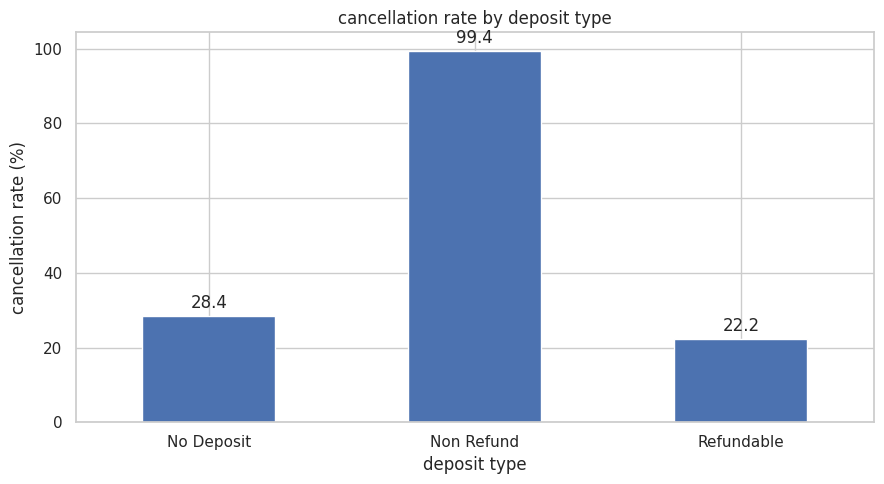

In [17]:
ax = result.plot(
    x="deposit_type",
    y="cancellation_rate_pct",
    kind="bar",
    figsize=(9,5),
    legend=False
)

plt.title("cancellation rate by deposit type")
plt.xlabel("deposit type")
plt.ylabel("cancellation rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
  ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

> **Original interpretation:** เราไม่ควรสรุปว่าเงื่อนไข Non Refund ทำให้ลูกค้ายกเลิก เพราะอาจมีปัจจัยอื่นเกี่ยวข้อง เช่น Market Segment หรือ Lead Time


### Deposit type × market segment


In [18]:
query = """
SELECT deposit_type,
      market_segment,
      COUNT(*) AS total_bookings,
      SUM(is_canceled) AS cancellation_bookings,
      ROUND(100.0 * sum(is_canceled) / count(*), 2) as cancellation_rate_pct
FROM hotel_df
GROUP BY deposit_type, market_segment
ORDER BY cancellation_rate_pct DESC;
"""
result = duckdb.sql(query).df()
display(result)

,deposit_type,market_segment,total_bookings,cancellation_bookings,cancellation_rate_pct
0,Refundable,Online TA,18,18.0,100.00
1,No Deposit,Undefined,2,2.0,100.00
2,Non Refund,Offline TA/TO,5006,5003.0,99.94
3,Non Refund,Groups,9172,9110.0,99.32
4,Non Refund,Online TA,56,53.0,94.64
5,Non Refund,Corporate,334,312.0,93.41
6,Non Refund,Direct,19,16.0,84.21
7,Refundable,Offline TA/TO,4,2.0,50.00
8,No Deposit,Online TA,56403,20668.0,36.64
9,Refundable,Direct,6,2.0,33.33


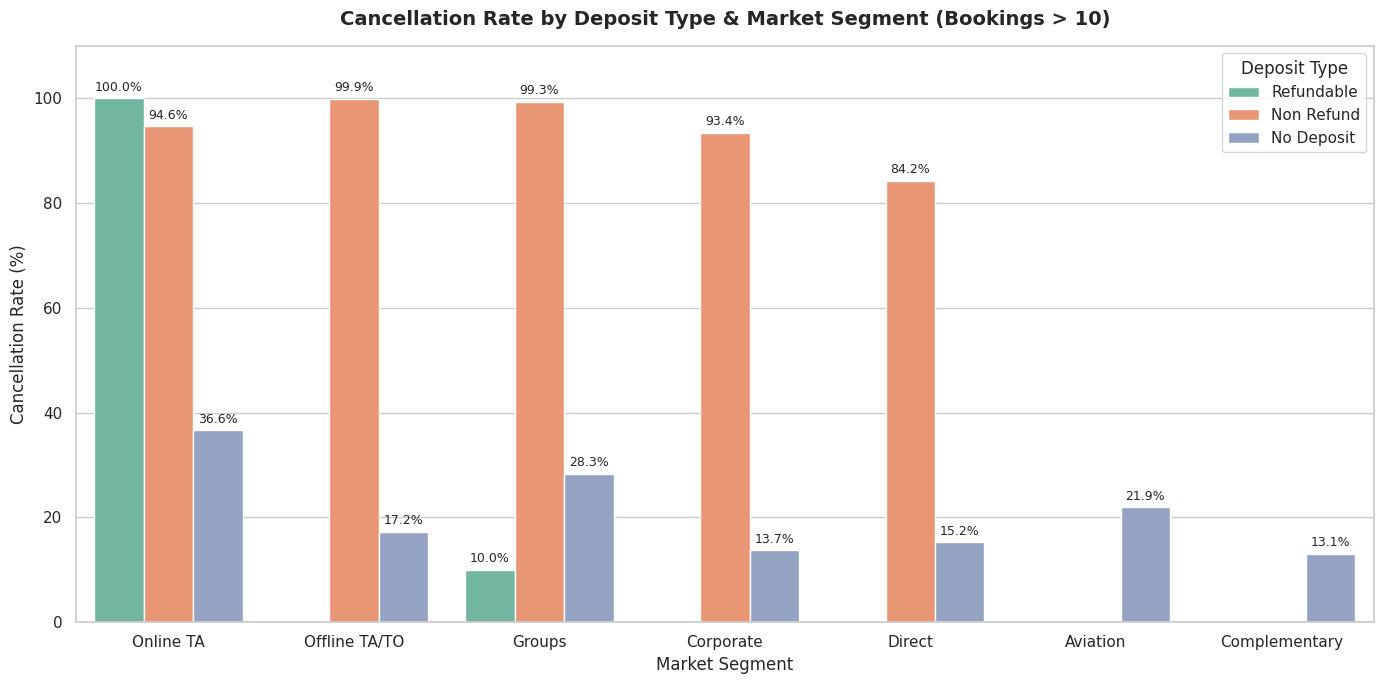

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าสไตล์ของกราฟ
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# กรองข้อมูลเพื่อโฟกัสกลุ่มที่มีการจองที่มีนัยสำคัญ (เช่น มียอดจองมากกว่า 10 ครั้ง เพื่อไม่ให้มีข้อมูลที่บิดเบือนจากสถิติกลุ่มย่อยเกินไป)
filtered_result = result[result['total_bookings'] > 10]

# สร้าง Grouped Bar Chart เปรียบเทียบตาม Deposit Type และ Market Segment
ax = sns.barplot(
    x="market_segment",
    y="cancellation_rate_pct",
    hue="deposit_type",
    data=filtered_result,
    palette="Set2"
)

# ใส่ป้ายแสดงตัวเลขเปอร์เซ็นต์บนแท่งกราฟ
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9)

# ตั้งชื่อกราฟและแกน
plt.title("Cancellation Rate by Deposit Type & Market Segment (Bookings > 10)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Market Segment", fontsize=12)
plt.ylabel("Cancellation Rate (%)", fontsize=12)
plt.ylim(0, 110)
plt.legend(title="Deposit Type", loc="upper right")

plt.tight_layout()
plt.show()

The original visualization limits categories to groups with more than 10 bookings. This is a display rule, not a statistical significance test.


### Deposit type × lead time


In [20]:
query = """
WITH lead_groups AS (
      SELECT
            deposit_type,
            is_canceled,
            CASE
              WHEN lead_time <= 30 THEN '0-30 days'
              WHEN lead_time <= 90 THEN '31-90 days'
              ELSE '91+ days'
            END AS lead_time_group
      FROM hotel_df
)

SELECT
      deposit_type,
      lead_time_group,
      COUNT(*) AS total_bookings,
      ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total_bookings,
      ROUND(100.0 * SUM(is_canceled) / COUNT(*), 2) AS cancellation_rate_pct
FROM lead_groups
GROUP BY deposit_type, lead_time_group
ORDER BY
      deposit_type,
      CASE lead_time_group
        WHEN '0-30 days' THEN 1
        WHEN '31-90 days' THEN 2
        WHEN '91+ days' THEN 3
      END;
"""

result = duckdb.sql(query).df()
display(result)

,deposit_type,lead_time_group,total_bookings,pct_total_bookings,cancellation_rate_pct
0,No Deposit,0-30 days,38057,31.88,17.34
1,No Deposit,31-90 days,27139,22.73,32.19
2,No Deposit,91+ days,39445,33.04,36.40
3,Non Refund,0-30 days,615,0.52,94.31
4,Non Refund,31-90 days,2406,2.02,99.79
5,Non Refund,91+ days,11566,9.69,99.54
6,Refundable,0-30 days,34,0.03,14.71
7,Refundable,31-90 days,8,0.01,50.00
8,Refundable,91+ days,120,0.10,22.50


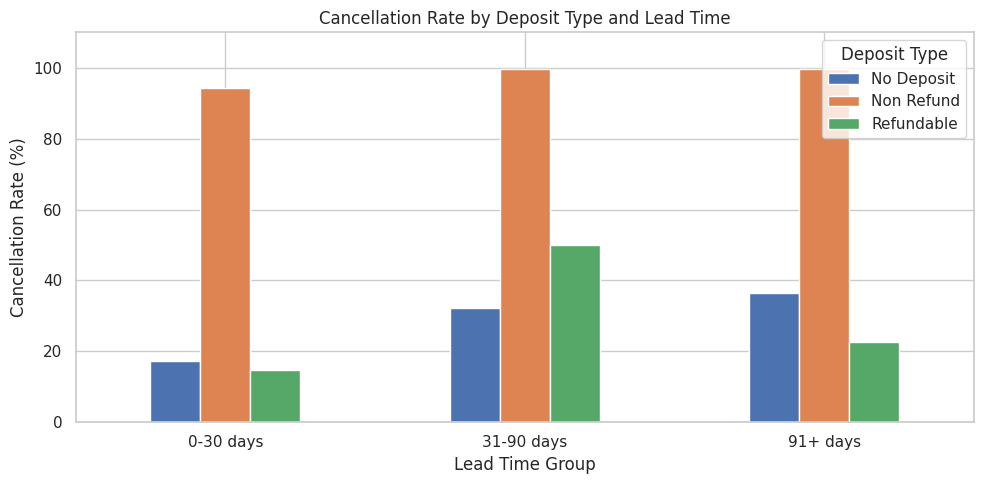

In [21]:
import matplotlib.pyplot as plt

chart_data = result.pivot(
    index="lead_time_group",
    columns="deposit_type",
    values="cancellation_rate_pct"
)

chart_data = chart_data.reindex(
    ["0-30 days", "31-90 days", "91+ days"]
)

ax = chart_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Cancellation Rate by Deposit Type and Lead Time")
plt.xlabel("Lead Time Group")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend(title="Deposit Type")

plt.tight_layout()
plt.show()

## 05. Data Integrity — Reservation Status

**Business question:** How does `reservation_status` relate to the recorded cancellation outcome?  
Reservation status describes the outcome and should not be presented as an advance warning signal. This section helps document the meaning and timing of fields.

In [22]:
query = """
SELECT reservation_status,
      COUNT(*) AS total_bookings,
      SUM(is_canceled) AS canceled_bookings,
      ROUND(100.0 * SUM(is_canceled) / COUNT(*), 2) AS cancellation_rate
FROM hotel_df
GROUP BY reservation_status
ORDER BY cancellation_rate DESC;
"""
result = duckdb.sql(query).df()
display(result)

,reservation_status,total_bookings,canceled_bookings,cancellation_rate
0,No-Show,1207,1207.0,100.0
1,Canceled,43017,43017.0,100.0
2,Check-Out,75166,0.0,0.0


**Interpretation:** `reservation_status` may contain information known only after the reservation outcome. Avoid using it as a pre-arrival explanatory risk factor.

## 06. Time Trends and Detailed Segmentation

**Business question:** How do cancellation patterns vary across years, months, segments, and hotel types?


### Yearly rates by hotel type


In [23]:
query = """
SELECT
    hotel,
    arrival_date_year,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(100.0 * SUM(is_canceled) / COUNT(*), 2) AS cancellation_rate_pct
FROM hotel_df
GROUP BY hotel, arrival_date_year
ORDER BY arrival_date_year ASC, hotel ASC;
"""
result = duckdb.sql(query).df()
display(result)

,hotel,arrival_date_year,total_bookings,canceled_bookings,cancellation_rate_pct
0,City Hotel,2015,13682,6004.0,43.88
1,Resort Hotel,2015,8314,2138.0,25.72
2,City Hotel,2016,38140,15407.0,40.40
3,Resort Hotel,2016,18567,4930.0,26.55
4,City Hotel,2017,27508,11691.0,42.50
5,Resort Hotel,2017,13179,4054.0,30.76


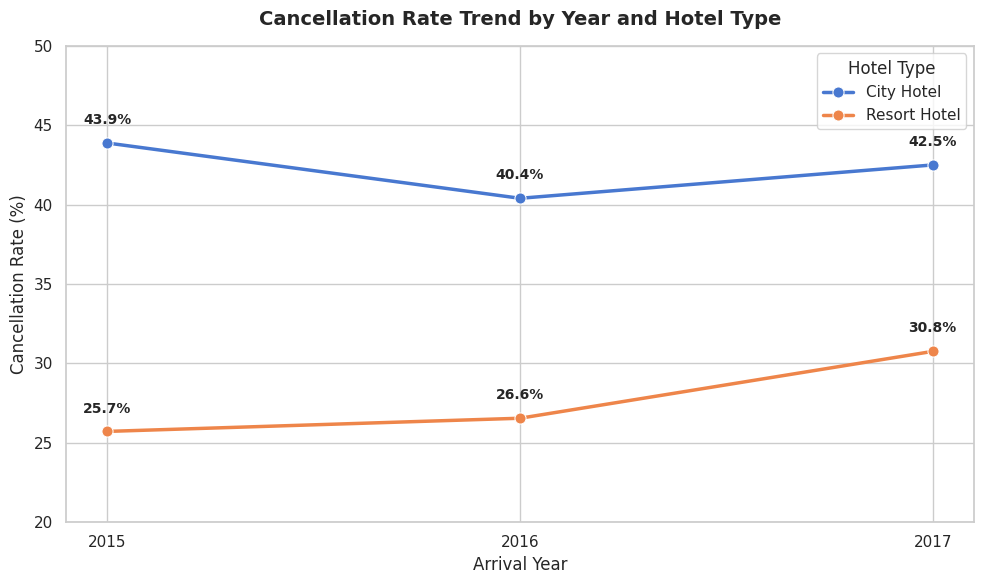

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create a line plot instead of a bar chart
ax = sns.lineplot(
    x="arrival_date_year",
    y="cancellation_rate_pct",
    hue="hotel",
    marker="o",
    markersize=8,
    linewidth=2.5,
    data=result,
    palette="muted"
)

# Add percentage labels above each marker point
for i in range(len(result)):
    row = result.iloc[i]
    plt.text(
        x=row['arrival_date_year'],
        y=row['cancellation_rate_pct'] + 1.0,
        s=f"{row['cancellation_rate_pct']:.1f}%",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.title("Cancellation Rate Trend by Year and Hotel Type", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Arrival Year", fontsize=12)
plt.ylabel("Cancellation Rate (%)", fontsize=12)
plt.ylim(20, 50)
# Set x-ticks to display only the actual integer years available in dataset
plt.xticks(result['arrival_date_year'].unique())
plt.legend(title="Hotel Type")

plt.tight_layout()
plt.show()

### Market segment × hotel type


In [25]:
query = """
SELECT
    hotel,
    market_segment,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(100.0 * SUM(is_canceled) / COUNT(*), 2) AS cancellation_rate_pct
FROM hotel_df
GROUP BY hotel, market_segment
ORDER BY hotel, cancellation_rate_pct DESC;
"""

result = duckdb.sql(query).df()
display(result)

,hotel,market_segment,total_bookings,canceled_bookings,cancellation_rate_pct
0,City Hotel,Undefined,2,2.0,100.00
1,City Hotel,Groups,13975,9623.0,68.86
2,City Hotel,Offline TA/TO,16747,7173.0,42.83
3,City Hotel,Online TA,38748,14491.0,37.40
4,City Hotel,Aviation,237,52.0,21.94
5,City Hotel,Corporate,2986,641.0,21.47
6,City Hotel,Direct,6093,1056.0,17.33
7,City Hotel,Complementary,542,64.0,11.81
8,Resort Hotel,Groups,5836,2474.0,42.39
9,Resort Hotel,Online TA,17729,6248.0,35.24


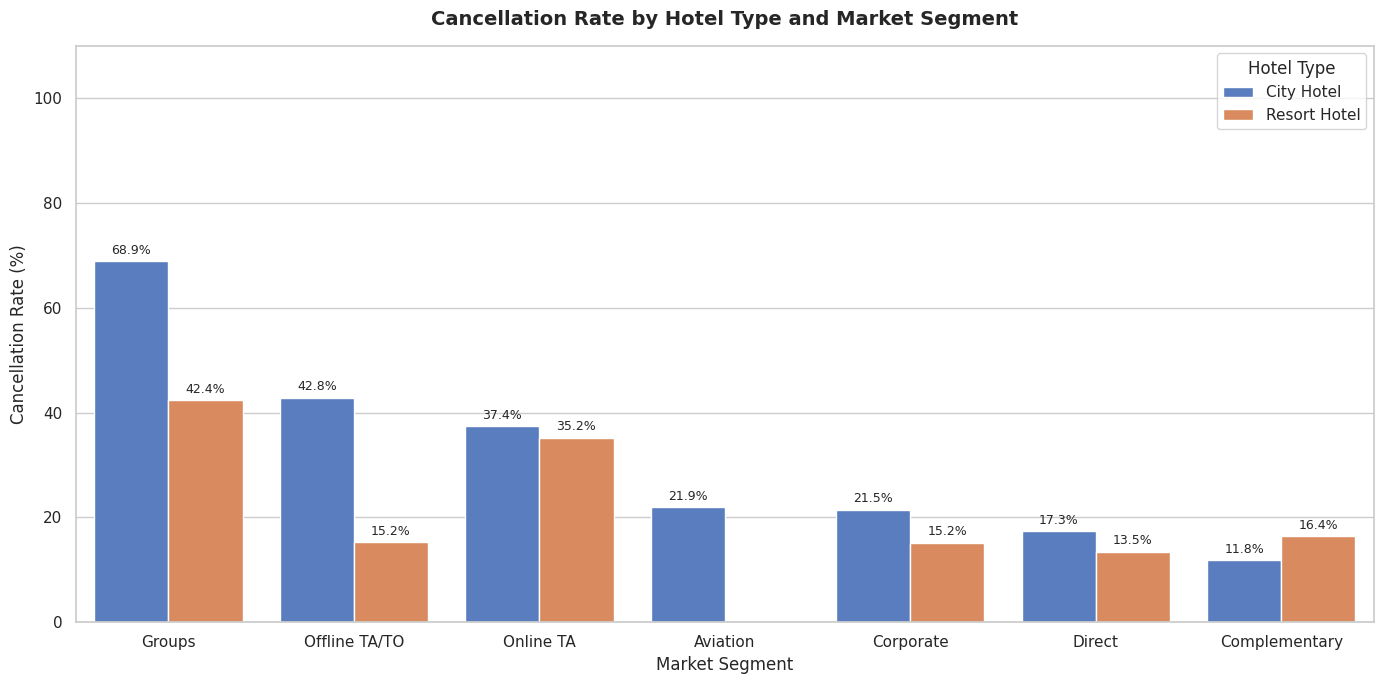

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# Filter out 'Undefined' market segment if it has very few bookings
filtered_result = result[result['total_bookings'] > 10]

# Create a Grouped Bar Chart
ax = sns.barplot(
    x="market_segment",
    y="cancellation_rate_pct",
    hue="hotel",
    data=filtered_result,
    palette="muted"
)

# Add labels on top of the bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9)

plt.title("Cancellation Rate by Hotel Type and Market Segment", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Market Segment", fontsize=12)
plt.ylabel("Cancellation Rate (%)", fontsize=12)
plt.ylim(0, 110)
plt.legend(title="Hotel Type")

plt.tight_layout()
plt.show()

### Online TA lead-time breakdown (pandas + SQL, with count check)


In [27]:
import pandas as pd
import duckdb

# STEP 1: Filter Online TA bookings
online = hotel_df[
    hotel_df["market_segment"] == "Online TA"
].copy()

# STEP 2: Create lead-time groups
bins = [-1, 7, 30, 90, 180, float("inf")]

labels = [
    "0-7 days",
    "8-30 days",
    "31-90 days",
    "91-180 days",
    "181+ days"
]

online["lead_time_group"] = pd.cut(
    online["lead_time"],
    bins=bins,
    labels=labels
)

# STEP 3: Analyze cancellation rates using SQL
query = """
SELECT
    hotel,
    lead_time_group,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(
        100.0 * SUM(is_canceled) / COUNT(*),
        2
    ) AS cancellation_rate_pct
FROM online
GROUP BY hotel, lead_time_group
ORDER BY hotel, lead_time_group
"""

result = duckdb.sql(query).df()

# STEP 4: Display results
display(result)

# STEP 5: Validate data
print("Original Online TA bookings:", len(online))
print("Grouped bookings:", result["total_bookings"].sum())

assert len(online) == result["total_bookings"].sum(), \
    "Validation failed: booking counts do not match!"

print("Validation passed!")

,hotel,lead_time_group,total_bookings,canceled_bookings,cancellation_rate_pct
0,City Hotel,0-7 days,4981,580.0,11.64
1,City Hotel,8-30 days,7680,2644.0,34.43
2,City Hotel,31-90 days,11770,4669.0,39.67
3,City Hotel,91-180 days,9423,4057.0,43.05
4,City Hotel,181+ days,4894,2541.0,51.92
5,Resort Hotel,0-7 days,3363,215.0,6.39
6,Resort Hotel,8-30 days,3248,855.0,26.32
7,Resort Hotel,31-90 days,4687,1854.0,39.56
8,Resort Hotel,91-180 days,3828,1849.0,48.30
9,Resort Hotel,181+ days,2603,1475.0,56.67


Original Online TA bookings: 56477
Grouped bookings: 56477
Validation passed!


### Monthly cancellation trend by hotel


In [28]:
import duckdb

query = """
SELECT
    hotel,
    arrival_date_year,
    arrival_date_month,
    count(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(100.0 * SUM(is_canceled) / COUNT(*), 2) AS cancellation_rate_pct
FROM hotel_df
GROUP BY hotel, arrival_date_year, arrival_date_month
ORDER BY arrival_date_year ASC, arrival_date_month ASC, hotel ASC;
"""

result = duckdb.sql(query).df()
display(result)

,hotel,arrival_date_year,arrival_date_month,total_bookings,canceled_bookings,cancellation_rate_pct
0,City Hotel,2015,August,2480,1232.0,49.68
1,Resort Hotel,2015,August,1409,366.0,25.98
2,City Hotel,2015,December,1654,668.0,40.39
3,Resort Hotel,2015,December,1266,305.0,24.09
4,City Hotel,2015,July,1398,939.0,67.17
5,Resort Hotel,2015,July,1378,320.0,23.22
6,City Hotel,2015,November,1235,301.0,24.37
7,Resort Hotel,2015,November,1105,185.0,16.74
8,City Hotel,2015,October,3386,1321.0,39.01
9,Resort Hotel,2015,October,1571,411.0,26.16


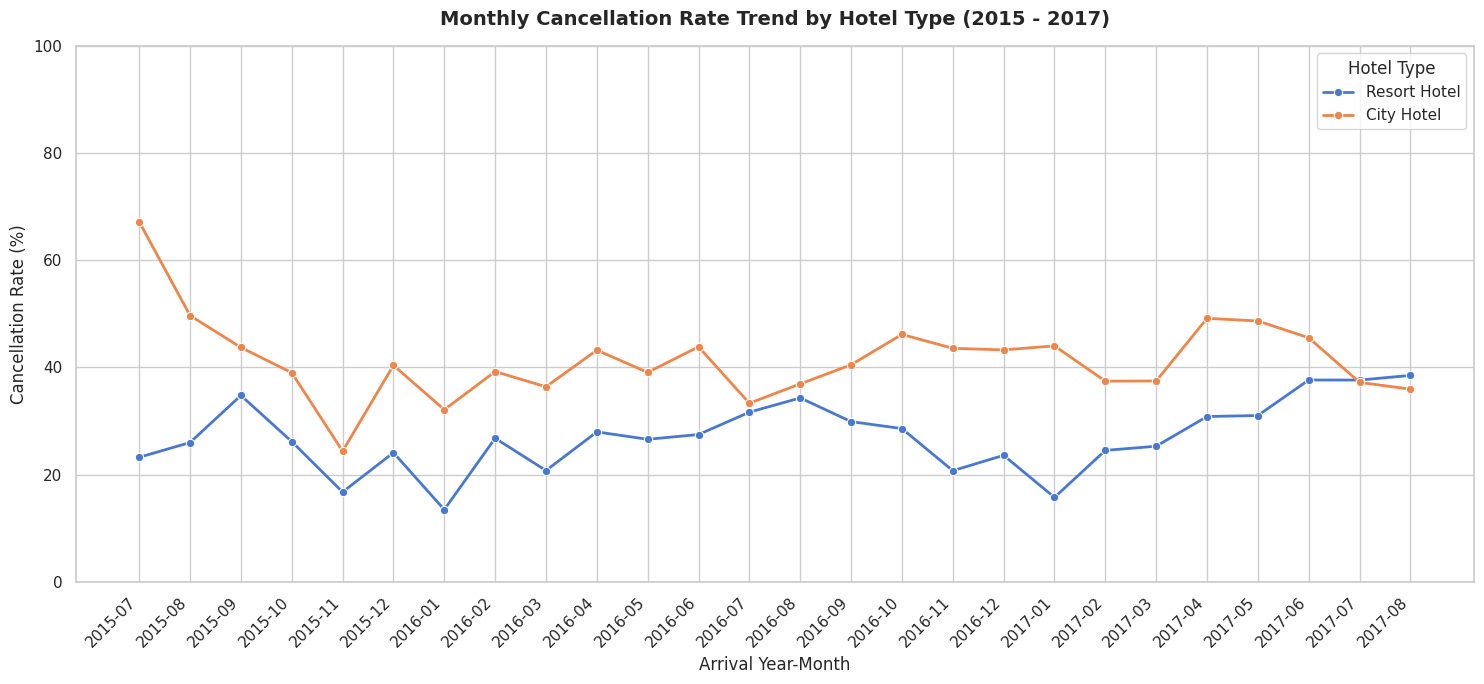

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Map month names to numbers for correct chronological sorting
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}

# Prepare the data
plot_df = result.copy()
plot_df['month_num'] = plot_df['arrival_date_month'].map(month_map)

# Combine year and month for a continuous time axis
plot_df['year_month'] = plot_df['arrival_date_year'].astype(str) + '-' + plot_df['month_num'].astype(str).str.zfill(2)
plot_df = plot_df.sort_values('year_month')

# Create the visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 7))

ax = sns.lineplot(
    x="year_month",
    y="cancellation_rate_pct",
    hue="hotel",
    marker="o",
    linewidth=2,
    data=plot_df,
    palette="muted"
)

plt.title("Monthly Cancellation Rate Trend by Hotel Type (2015 - 2017)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Arrival Year-Month", fontsize=12)
plt.ylabel("Cancellation Rate (%)", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.legend(title="Hotel Type")

plt.tight_layout()
plt.show()

**Note:** This original monthly code maps month names to numbers and sorts the combined year-month string. This is **scheduled arrival month**, not booking creation month. Partial years should not be compared as if they contained 12 months each.


## 07. Estimated Value Associated with Canceled Bookings

**Business question:** Which segment has the greatest **estimated value of canceled bookings**?


The original calculation estimates booking value as `ADR × total nights`. It is **not observed revenue loss**, realized revenue, or profit. Exclusions for nonpositive nights and negative ADR are explicitly checked in the code below.


### Data-quality checks, canceled value, and excluded records


In [30]:
import pandas as pd
import duckdb

# STEP 1: Create calculated columns
hotel_df["total_nights"] = (
    hotel_df["stays_in_weekend_nights"]
    + hotel_df["stays_in_week_nights"]
)

hotel_df["booking_value"] = (
    hotel_df["total_nights"] * hotel_df["adr"]
)

# STEP 2: Check data quality
quality_query = """
SELECT
    COUNT(*) AS total_bookings,
    SUM(CASE WHEN total_nights = 0 THEN 1 ELSE 0 END)
        AS zero_night_bookings,
    SUM(CASE WHEN adr < 0 THEN 1 ELSE 0 END)
        AS negative_adr,
    SUM(CASE WHEN adr = 0 THEN 1 ELSE 0 END)
        AS zero_adr
FROM hotel_df
"""

print("DATA QUALITY CHECK")
display(duckdb.sql(quality_query).df())

# STEP 3: Analyze canceled booking values
query = """
SELECT
    hotel,
    market_segment,
    COUNT(*) AS canceled_bookings,
    ROUND(SUM(booking_value), 2)
        AS canceled_booking_value

FROM hotel_df

WHERE is_canceled = 1
  AND total_nights > 0
  AND adr >= 0

GROUP BY
    hotel,
    market_segment

ORDER BY
    canceled_booking_value DESC
"""

result = duckdb.sql(query).df()

print("CANCELED BOOKING VALUE BY SEGMENT")
display(result)

# STEP 4: Check how many canceled records were excluded
validation_query = """
SELECT
    COUNT(*) AS all_canceled_bookings,
    SUM(
        CASE
            WHEN total_nights <= 0
              OR adr < 0
              OR adr IS NULL
              OR total_nights IS NULL
            THEN 1
            ELSE 0
        END
    ) AS excluded_canceled_bookings
FROM hotel_df
WHERE is_canceled = 1
"""

print("EXCLUSION CHECK")
display(duckdb.sql(validation_query).df())

DATA QUALITY CHECK


,total_bookings,zero_night_bookings,negative_adr,zero_adr
0,119390,715.0,1.0,1959.0


CANCELED BOOKING VALUE BY SEGMENT


,hotel,market_segment,canceled_bookings,canceled_booking_value
0,City Hotel,Online TA,14482,6222700.93
1,Resort Hotel,Online TA,6242,4004945.18
2,City Hotel,Groups,9623,2141202.55
3,City Hotel,Offline TA/TO,7173,1921160.65
4,Resort Hotel,Groups,2473,659341.43
5,Resort Hotel,Offline TA/TO,1135,571197.50
6,Resort Hotel,Direct,877,528628.38
7,City Hotel,Direct,1053,464781.44
8,City Hotel,Corporate,640,118393.22
9,Resort Hotel,Corporate,350,77989.85


EXCLUSION CHECK


,all_canceled_bookings,excluded_canceled_bookings
0,44224,35.0


### Canceled booking value by hotel and segment


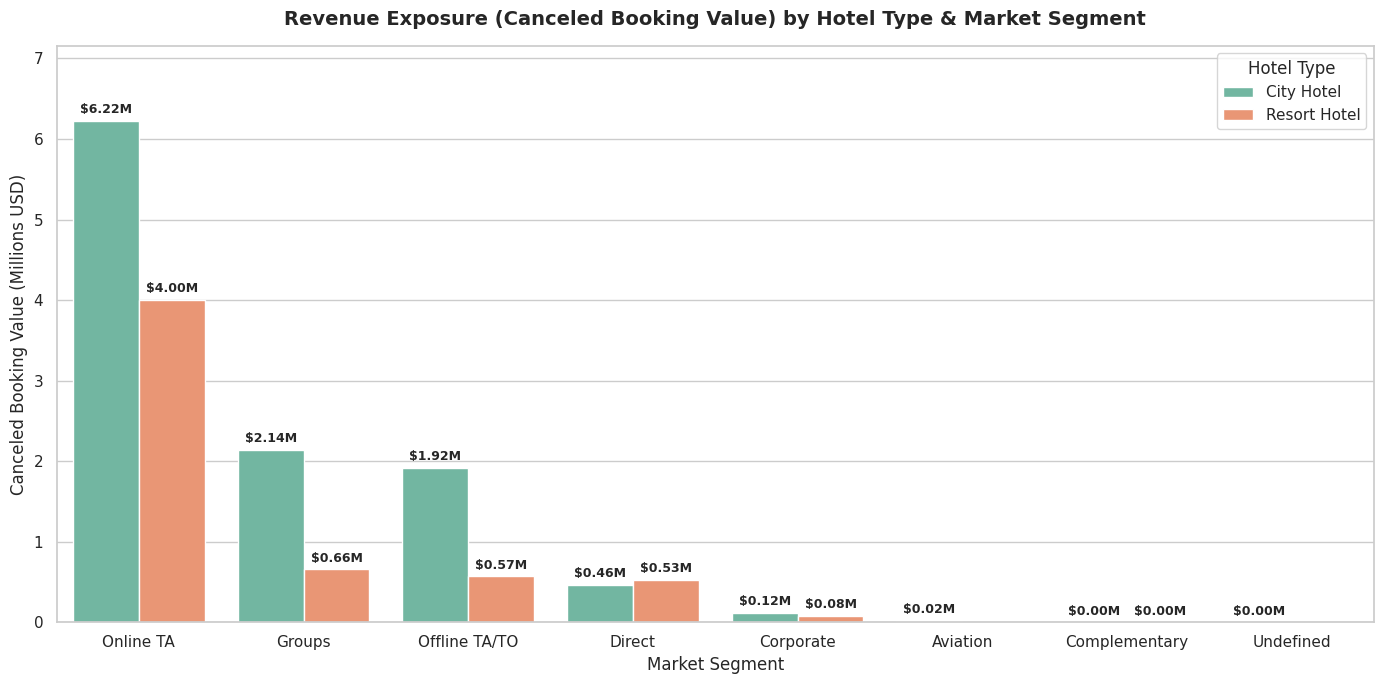

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style and figure size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# Create a copy of the result data and convert value to Millions for better readability
plot_revenue_df = result.copy()
plot_revenue_df['canceled_booking_value_m'] = plot_revenue_df['canceled_booking_value'] / 1_000_000

# Create grouped bar chart
ax = sns.barplot(
    x="market_segment",
    y="canceled_booking_value_m",
    hue="hotel",
    data=plot_revenue_df,
    palette="Set2"
)

# Add value labels on top of the bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'${p.get_height():.2f}M',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9,
                    fontweight='bold')

# Set labels and title
plt.title("Revenue Exposure (Canceled Booking Value) by Hotel Type & Market Segment", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Market Segment", fontsize=12)
plt.ylabel("Canceled Booking Value (Millions USD)", fontsize=12)
plt.ylim(0, plot_revenue_df['canceled_booking_value_m'].max() * 1.15)
plt.legend(title="Hotel Type", loc="upper right")

plt.tight_layout()
plt.show()

### Average canceled booking value


In [32]:
result["avg_canceled_booking_value"] = (
    result["canceled_booking_value"]
    / result["canceled_bookings"]
).round(2)

display(
    result[
        [
            "hotel",
            "market_segment",
            "canceled_bookings",
            "canceled_booking_value",
            "avg_canceled_booking_value"
        ]
    ].sort_values(
        "avg_canceled_booking_value",
        ascending=False
    )
)

,hotel,market_segment,canceled_bookings,canceled_booking_value,avg_canceled_booking_value
1,Resort Hotel,Online TA,6242,4004945.18,641.61
6,Resort Hotel,Direct,877,528628.38,602.77
5,Resort Hotel,Offline TA/TO,1135,571197.50,503.26
7,City Hotel,Direct,1053,464781.44,441.39
0,City Hotel,Online TA,14482,6222700.93,429.69
10,City Hotel,Aviation,51,16578.00,325.06
3,City Hotel,Offline TA/TO,7173,1921160.65,267.83
4,Resort Hotel,Groups,2473,659341.43,266.62
9,Resort Hotel,Corporate,350,77989.85,222.83
2,City Hotel,Groups,9623,2141202.55,222.51


### Canceled vs non-canceled estimated booking value


In [33]:
import duckdb

query = """
WITH base AS (
    SELECT
        hotel,
        market_segment,
        is_canceled,
        CASE
            WHEN adr >= 0
             AND stays_in_weekend_nights
                 + stays_in_week_nights > 0
            THEN adr * (
                stays_in_weekend_nights
                + stays_in_week_nights
            )
            ELSE NULL
        END AS booking_value
    FROM hotel_df
)

SELECT
    hotel,
    market_segment,

    COUNT(*) AS total_bookings,

    SUM(is_canceled) AS canceled_bookings,

    ROUND(
        100.0 * SUM(is_canceled) / COUNT(*), 2
    ) AS cancellation_rate_pct,

    ROUND(
        SUM(CASE WHEN is_canceled = 0
            THEN booking_value ELSE 0 END), 2
    ) AS non_canceled_booking_value,

    ROUND(
        SUM(CASE WHEN is_canceled = 1
            THEN booking_value ELSE 0 END), 2
    ) AS canceled_booking_value,

    ROUND(
        100.0 *
        SUM(CASE WHEN is_canceled = 1
            THEN booking_value ELSE 0 END)
        / NULLIF(SUM(booking_value), 0), 2
    ) AS canceled_value_share_pct

FROM base

WHERE hotel = 'City Hotel'

GROUP BY hotel, market_segment

ORDER BY canceled_booking_value DESC
"""

result = duckdb.sql(query).df()
display(result)

,hotel,market_segment,total_bookings,canceled_bookings,cancellation_rate_pct,non_canceled_booking_value,canceled_booking_value,canceled_value_share_pct
0,City Hotel,Online TA,38748,14491.0,37.40,8762543.52,6222700.93,41.53
1,City Hotel,Groups,13975,9623.0,68.86,980788.50,2141202.55,68.58
2,City Hotel,Offline TA/TO,16747,7173.0,42.83,2554041.33,1921160.65,42.93
3,City Hotel,Direct,6093,1056.0,17.33,1657750.07,464781.44,21.90
4,City Hotel,Corporate,2986,641.0,21.47,365675.40,118393.22,24.46
5,City Hotel,Aviation,237,52.0,21.94,70868.36,16578.00,18.96
6,City Hotel,Complementary,542,64.0,11.81,2743.00,194.99,6.64
7,City Hotel,Undefined,2,2.0,100.00,0.00,48.00,100.00


**Interpretation from original notes:** รวม Online TA ก็ยังสำคัญมาก แต่ยังสรุปไม่ได้ว่า Online TA สร้างกำไรสูงสุด เพราะเรายังไม่ได้หักค่าคอมมิชชัน ต้นทุน และตรวจสอบรายได้ที่รับรู้จริง

**Currency caveat:** The original chart labels the value as USD; this notebook has not independently verified that currency label from the source.


## 09. Summary and Limitations

**Main historical findings (verify again after running):**
- City Hotel cancellation rate: **41.73%**, versus **27.76%** for Resort Hotel.
- **Online TA** has more canceled bookings (**20,739**) than **Groups** (**12,097**), even though Groups has a higher cancellation rate (**61.06%** versus **36.72%**).
- The **91+ days** lead-time group has a **50.65%** cancellation rate, compared with **18.56%** for **0–30 days**.

**Potential business follow-up:** Prioritize investigating high-volume canceled-booking segments, and examine long-lead-time reservations within each hotel before testing operational interventions.

**Limitations:**
- Observational relationships do not establish causality.
- Arrival month is **not** the date the booking was created, and the available years are incomplete at their edges.
- ADR × total nights estimates booked value associated with cancellation; it is **not** measured lost revenue or profit.
- Test results and findings should be confirmed by re-running all cells before publishing.

**Next step:** The separate optional prediction notebook extends the same Hotel Booking dataset; it is not required to understand this descriptive project.